# Thực nghiệm — Thử tham số cho 4 mô hình trên tập A+B
 
**Tập dữ liệu:** A+B (38 đặc trưng: 36 đặc trưng gốc và 2 đặc trưng bổ sung của học kỳ 1)  
**Đánh giá:** Stratified 5-fold Cross Validation, `shuffle=True`, `random_state=42`; chỉ số chính là CV Macro-F1.

Notebook này sử dụng **đúng các cấu hình Gốc và Thử đã dùng trong notebook tập A**. Như vậy, khi so sánh A với A+B, chỉ khác tập đặc trưng; không đồng thời thay đổi siêu tham số. Mỗi cấu hình Thử chỉ thay đổi một tham số thuộc cấu hình mốc; các tham số còn lại được giữ nguyên.

## 1. Tham số thực nghiệm



In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Tìm thư mục gốc dự án để notebook chạy được khi mở từ thư mục experiments.
cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
        and (folder / "data" / "processed" / "development.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy ML01_Student_Dropout/feature_b/common.py và "
        "data/processed/development.csv. Hãy mở repo sgu-MAYHOC trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-18_ThuThamSo_4MoHinh_TapAB_Khoi"
a_output_dir = project_dir / "experiments" / "2026-11-18_ThuThamSo_4MoHinh_TapA_Khoi"

N_FOLDS = 5
SEED = 42

# Cấu hình Gốc theo mốc chung; cấu hình Thử thống nhất với notebook tập A.
configs = {
    "Logistic Regression": {
        "class": LogisticRegression,
        "scale_numeric": True,
        "baseline": {
            "C": 0.1,
            "class_weight": "balanced",
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "trial": {
            "C": 0.1,
            "class_weight": None,
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "changed_parameter": "class_weight: 'balanced' -> None",
    },
    "Random Forest": {
        "class": RandomForestClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_leaf": 1,
            "class_weight": "balanced",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_leaf": 1,
            "class_weight": None,
            "random_state": SEED,
            "n_jobs": 1,
        },
        "changed_parameter": "class_weight: 'balanced' -> None",
    },
    "SVM": {
        "class": SVC,
        "scale_numeric": True,
        "baseline": {
            "kernel": "rbf",
            "C": 10,
            "gamma": 0.01,
            "class_weight": "balanced",
        },
        "trial": {
            "kernel": "rbf",
            "C": 5,
            "gamma": 0.01,
            "class_weight": "balanced",
        },
        "changed_parameter": "C: 10 -> 5",
    },
    "XGBoost": {
        "class": XGBClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 150,
            "max_depth": 6,
            "learning_rate": 0.1,
            "objective": "multi:softprob",
            "num_class": 3,
            "eval_metric": "mlogloss",
            "tree_method": "hist",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 150,
            "max_depth": 5,
            "learning_rate": 0.1,
            "objective": "multi:softprob",
            "num_class": 3,
            "eval_metric": "mlogloss",
            "tree_method": "hist",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "changed_parameter": "max_depth: 6 -> 5",
    },
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thay đổi": item["changed_parameter"],
        "Cấu hình Gốc": ", ".join(
            f"{key}={value!r}" for key, value in item["baseline"].items()
        ),
        "Cấu hình Thử": ", ".join(
            f"{key}={value!r}" for key, value in item["trial"].items()
        ),
    }
    for name, item in configs.items()
])
display(config_table)

print("Project:", project_dir)
print("Dữ liệu:", data_path)
print("Thư mục lưu kết quả:", output_dir)

,Mô hình,Tham số thay đổi,Cấu hình Gốc,Cấu hình Thử
0,Logistic Regression,class_weight: 'balanced' -> None,"C=0.1, class_weight='balanced', solver='lbfgs'...","C=0.1, class_weight=None, solver='lbfgs', max_..."
1,Random Forest,class_weight: 'balanced' -> None,"n_estimators=200, max_depth=None, min_samples_...","n_estimators=200, max_depth=None, min_samples_..."
2,SVM,C: 10 -> 5,"kernel='rbf', C=10, gamma=0.01, class_weight='...","kernel='rbf', C=5, gamma=0.01, class_weight='b..."
3,XGBoost,max_depth: 6 -> 5,"n_estimators=150, max_depth=6, learning_rate=0...","n_estimators=150, max_depth=5, learning_rate=0..."


Project: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout
Dữ liệu: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\data\processed\development.csv
Thư mục lưu kết quả: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-18_ThuThamSo_4MoHinh_TapAB_Khoi


## 2. Huấn luyện và đánh giá trên tập A+B

Sử dụng `load_development()` và `evaluate()` trong `feature_b/common.py` để thống nhất cách tiền xử lý với các thực nghiệm hiện có. Cùng một danh sách fold phân tầng được dùng cho cả cấu hình Gốc và cấu hình Thử của bốn mô hình.

In [2]:
X_a, X_ab, y = load_development(data_path)
assert X_ab.shape[1] == 38, f"Tập A+B phải có 38 đặc trưng, hiện có {X_ab.shape[1]}."

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []

for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        version_label = "Gốc" if version == "baseline" else "Thử"
        print(f"Đang đánh giá trên A+B: {model_name} - {version_label}")

        model = item["class"](**item[version])
        summary, fold_scores = evaluate(
            model_name,
            model,
            item["scale_numeric"],
            "A+B",
            X_ab,
            y,
            folds,
        )
        summary["Cấu hình"] = version_label
        summary_rows.append(summary)

        fold_scores = fold_scores.copy()
        fold_scores["Cấu hình"] = version_label
        fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)

display(
    results[["model", "Cấu hình", "cv_macro_f1",
             "oof_recall_dropout", "oof_recall_enrolled",
             "oof_recall_graduate"]].round(6)
)

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá trên A+B: Logistic Regression - Gốc
Đang đánh giá trên A+B: Logistic Regression - Thử
Đang đánh giá trên A+B: Random Forest - Gốc
Đang đánh giá trên A+B: Random Forest - Thử
Đang đánh giá trên A+B: SVM - Gốc
Đang đánh giá trên A+B: SVM - Thử
Đang đánh giá trên A+B: XGBoost - Gốc
Đang đánh giá trên A+B: XGBoost - Thử


,model,Cấu hình,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Logistic Regression,Gốc,0.717317,0.730871,0.618898,0.825693
1,Logistic Regression,Thử,0.693763,0.775726,0.341732,0.934352
2,Random Forest,Gốc,0.723427,0.753738,0.530709,0.874363
3,Random Forest,Thử,0.691325,0.782762,0.321260,0.940011
4,SVM,Gốc,0.717298,0.738786,0.595276,0.835314
5,SVM,Thử,0.721357,0.730871,0.623622,0.831353
6,XGBoost,Gốc,0.708953,0.766931,0.423622,0.910017
7,XGBoost,Thử,0.713301,0.772208,0.426772,0.913413


## 3. So sánh cấu hình Gốc và cấu hình Thử trên A+B

Chênh lệch được tính bằng **CV Macro-F1 Thử − CV Macro-F1 Gốc** trên cùng tập A+B. Giá trị dương thể hiện cấu hình Thử tốt hơn trong lần đánh giá này; giá trị âm thể hiện cấu hình Gốc tốt hơn.

In [4]:
comparison_rows = []
for model_name, item in configs.items():
    model_rows = results.loc[results["model"].eq(model_name)].set_index("Cấu hình")
    baseline_score = float(model_rows.loc["Gốc", "cv_macro_f1"])
    trial_score = float(model_rows.loc["Thử", "cv_macro_f1"])

    comparison_rows.append({
        "Mô hình": model_name,
        "Tham số thay đổi": item["changed_parameter"],
        "CV Macro-F1 Gốc": baseline_score,
        "CV Macro-F1 Thử": trial_score,
        "Chênh lệch (Thử - Gốc)": trial_score - baseline_score,
    })

comparison_ab = (
    pd.DataFrame(comparison_rows)
    .sort_values("CV Macro-F1 Thử", ascending=False)
    .reset_index(drop=True)
)
display(comparison_ab.round(6))

best_trial = comparison_ab.iloc[0]
print(
    "Cấu hình Thử có CV Macro-F1 cao nhất trên A+B: "
    f"{best_trial['Mô hình']} ({best_trial['CV Macro-F1 Thử']:.6f})."
)

,Mô hình,Tham số thay đổi,CV Macro-F1 Gốc,CV Macro-F1 Thử,Chênh lệch (Thử - Gốc)
0,SVM,C: 10 -> 5,0.717298,0.721357,0.004059
1,XGBoost,max_depth: 6 -> 5,0.708953,0.713301,0.004347
2,Logistic Regression,class_weight: 'balanced' -> None,0.717317,0.693763,-0.023554
3,Random Forest,class_weight: 'balanced' -> None,0.723427,0.691325,-0.032102


Cấu hình Thử có CV Macro-F1 cao nhất trên A+B: SVM (0.721357).


## 4. Đối chiếu kết quả A thử và A+B thử

Đọc kết quả từ notebook tập A đã chạy, không nhập điểm thủ công. So sánh A+B Thử − A Thử để quan sát thay đổi khi bổ sung hai đặc trưng B trong cùng cấu hình tham số.

In [5]:
a_excel_path = a_output_dir / "ket_qua.xlsx"
if not a_excel_path.is_file():
    raise FileNotFoundError(
        f"Chưa tìm thấy {a_excel_path}. Hãy chạy xong notebook tập A trước, "
        "sau đó chạy lại cell này."
    )

a_results = pd.read_excel(a_excel_path, sheet_name="Tong hop")
required_columns = {"model", "Cấu hình", "cv_macro_f1"}
if not required_columns.issubset(a_results.columns):
    raise ValueError(
        "Sheet 'Tong hop' của kết quả tập A phải có các cột model, Cấu hình, cv_macro_f1."
    )

a_trial_scores = (
    a_results.loc[a_results["Cấu hình"].eq("Thử")]
    .set_index("model")["cv_macro_f1"]
)
ab_trial_scores = (
    results.loc[results["Cấu hình"].eq("Thử")]
    .set_index("model")["cv_macro_f1"]
)

comparison_a_ab = pd.DataFrame([
    {
        "Mô hình": model_name,
        "Tham số thay đổi": item["changed_parameter"],
        "A Thử": float(a_trial_scores.loc[model_name]),
        "A+B Thử": float(ab_trial_scores.loc[model_name]),
        "Chênh lệch (A+B Thử - A Thử)": (
            float(ab_trial_scores.loc[model_name])
            - float(a_trial_scores.loc[model_name])
        ),
    }
    for model_name, item in configs.items()
]).sort_values("A+B Thử", ascending=False).reset_index(drop=True)

display(comparison_a_ab.round(6))

,Mô hình,Tham số thay đổi,A Thử,A+B Thử,Chênh lệch (A+B Thử - A Thử)
0,SVM,C: 10 -> 5,0.723261,0.721357,-0.001904
1,XGBoost,max_depth: 6 -> 5,0.708740,0.713301,0.004561
2,Logistic Regression,class_weight: 'balanced' -> None,0.694601,0.693763,-0.000838
3,Random Forest,class_weight: 'balanced' -> None,0.676577,0.691325,0.014748


## 5. Biểu đồ và lưu kết quả



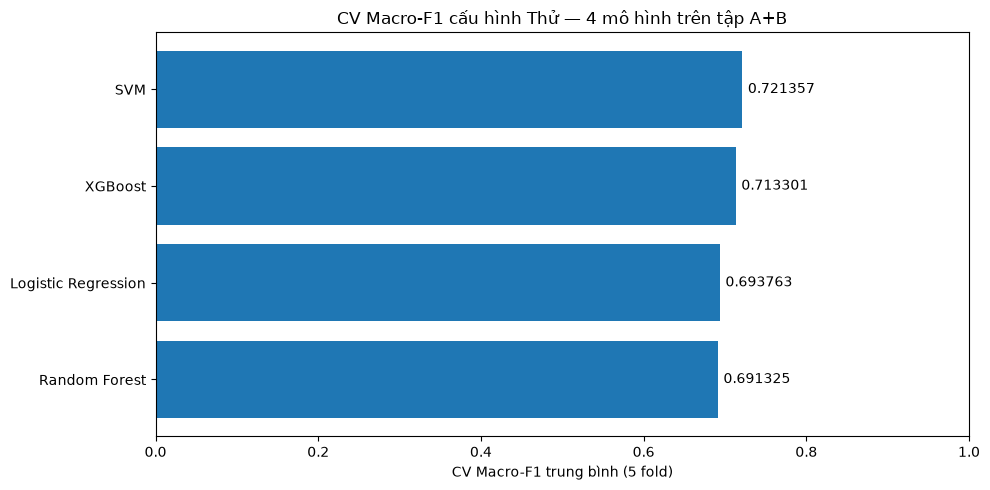

Đã lưu kết quả vào: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-18_ThuThamSo_4MoHinh_TapAB_Khoi
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_goc_va_thu.csv
 - so_sanh_A_va_AB.csv
 - so_sanh_macro_f1.png


In [6]:
output_dir.mkdir(parents=True, exist_ok=True)

excel_path = output_dir / "ket_qua.xlsx"
summary_path = output_dir / "ket_qua_tong_hop.csv"
fold_path = output_dir / "diem_tung_fold.csv"
comparison_path = output_dir / "so_sanh_goc_va_thu.csv"
a_ab_comparison_path = output_dir / "so_sanh_A_va_AB.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Nguyễn Hoàng Khởi",
    "Ngày thực nghiệm": "18/11/2026",
    "Tập đặc trưng": "A+B",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_ab.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số chính": "CV Macro-F1 trung bình",
    "scikit-learn": sklearn.__version__,
    "Thay đổi tham số": (
        "LR: class_weight 'balanced' -> None; "
        "RF: class_weight 'balanced' -> None; "
        "SVM: C 10 -> 5; XGBoost: max_depth 6 -> 5"
    ),
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison_ab.to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    comparison_a_ab.to_excel(writer, sheet_name="So sanh A va AB", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin", index=False)

results.to_csv(summary_path, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_path, index=False, encoding="utf-8-sig")
comparison_ab.to_csv(comparison_path, index=False, encoding="utf-8-sig")
comparison_a_ab.to_csv(a_ab_comparison_path, index=False, encoding="utf-8-sig")

plot_data = comparison_ab.sort_values("CV Macro-F1 Thử", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_data["Mô hình"], plot_data["CV Macro-F1 Thử"])
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("CV Macro-F1 cấu hình Thử — 4 mô hình trên tập A+B")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()
plt.close(fig)

print("Đã lưu kết quả vào:", output_dir.resolve())
for path in (
    excel_path, summary_path, fold_path, comparison_path,
    a_ab_comparison_path, image_path
):
    print(" -", path.name)

## 6. Nhận xét

Sau khi chạy toàn bộ notebook, dựa vào các bảng kết quả để ghi nhận:

- Mô hình có CV Macro-F1 cao nhất trong bốn cấu hình Thử trên A+B.
- Với từng mô hình, cấu hình Thử tăng hay giảm so với cấu hình Gốc trên cùng tập A+B.
- So sánh A+B Thử với A Thử để nhận xét thay đổi khi bổ sung hai đặc trưng B.
- Chỉ kết luận trong phạm vi các cấu hình và dữ liệu đã thử; không dùng điểm của một fold riêng lẻ để kết luận.